<a href="https://colab.research.google.com/github/DiegoMartell/Deep-Learning/blob/main/Hands-on/Hands_on_4_MLP_iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Perceptrón Multicapa (MLP) From Scratch - Dataset Iris
**Guía paso a paso para la clasificación de patrones implementando una Red Neuronal Artificial desde cero con Python y NumPy.**

>**¿Qué cambia respecto a la versión con Scikit-Learn?**
> * ** 1. **Sin librerías de alto nivel para el modelo:** En lugar de importar `from sklearn.neural_network import MLPClassifier`
> * **Fórmulas explícitas:** La propagación hacia adelante (*Forward*), el cálculo del error (*Loss*) y la actualización de pesos (*Backpropagation*) se calculan matemáticamente paso a paso.
> * **Métricas nativas:** Se conservan las métricas de evaluación (**Accuracy**, **Matriz de Confusión** y **Fronteras de Decisión**), calculadas con NumPy.

## 1. Fundamentos Teóricos del Perceptrón Multicapa
Un **Perceptrón Multicapa (MLP)** es una red neuronal de alimentación hacia adelante (*feedforward*) organizada en capas de neuronas interconectadas:
1. **Capa de Entrada (Input Layer):** Recibe las 4 características morfológicas de la flor Iris (longitud y ancho de sépalos y pétalos).
2. **Capas Ocultas (Hidden Layers):** Combinan las entradas con pesos y sesgos, aplicando una función de activación no lineal (**ReLU**) para doblar y separar el espacio geométrico.
3. **Capa de Salida (Output Layer):** Entrega la predicción mediante una distribución de probabilidades continuas con **Softmax** para las 3 especies de flores.

## 2. Modelo Matemático del MLP From Scratch

### A. Propagación hacia Adelante (*Forward Pass*)
Para cada muestra $X$ pasando a través de la red:
1. **Capa oculta (Lineal + ReLU):**
   $$Z_1 = X \cdot W_1 + b_1$$
   $$A_1 = \max(0, Z_1)$$
2. **Capa de salida (Lineal + Softmax):**
   $$Z_2 = A_1 \cdot W_2 + b_2$$
   $$\hat{y} = \text{Softmax}(Z_2) = \frac{e^{Z_2}}{\sum e^{Z_2}}$$

### B. Función de Pérdida y Retropropagación (*Backpropagation*)
* **Entropía Cruzada Categórica:** Mide el error entre las probabilidades predichas $\hat{y}$ y las etiquetas reales en *One-Hot* $y$:
  $$J(W) = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{3} y_{ik} \log(\hat{y}_{ik})$$
* **Gradientes y actualización:** Aplicando la regla de la cadena, los pesos se corrigen proporcionalmente al error:
  $$\delta_2 = \hat{y} - y, \quad \frac{\partial J}{\partial W_2} = \frac{1}{N} A_1^T \delta_2$$
  $$W := W - \alpha \cdot \frac{\partial J}{\partial W}$$
  *(donde $\alpha$ es la tasa de aprendizaje o learning rate)*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Fijamos semilla para reproducibilidad idéntica
np.random.seed(42)
print("✅ Librerías cargadas exitosamente.")

✅ Librerías cargadas exitosamente.


## 3. Pipeline de Machine Learning

### 3.1 Selección y Descripción del Dataset Iris
El conjunto de datos **Iris** consta de 150 instancias distribuidas equitativamente (50 muestras de cada una) en 3 especies:
* **Variables independientes ($X$):** `sepal_length`, `sepal_width`, `petal_length`, `petal_width` (en cm).
* **Variable dependiente ($Y$):** `species` (`Iris-setosa`, `Iris-versicolor`, `Iris-virginica`).

> **¿Qué cambia aquí?**
> Se carga el archivo CSV original directamente desde el repositorio de GitHub asignando los nombres de columna.

Primeras 5 filas del dataset Iris:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



Dimensiones de X: (150, 4)
Clases únicas: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


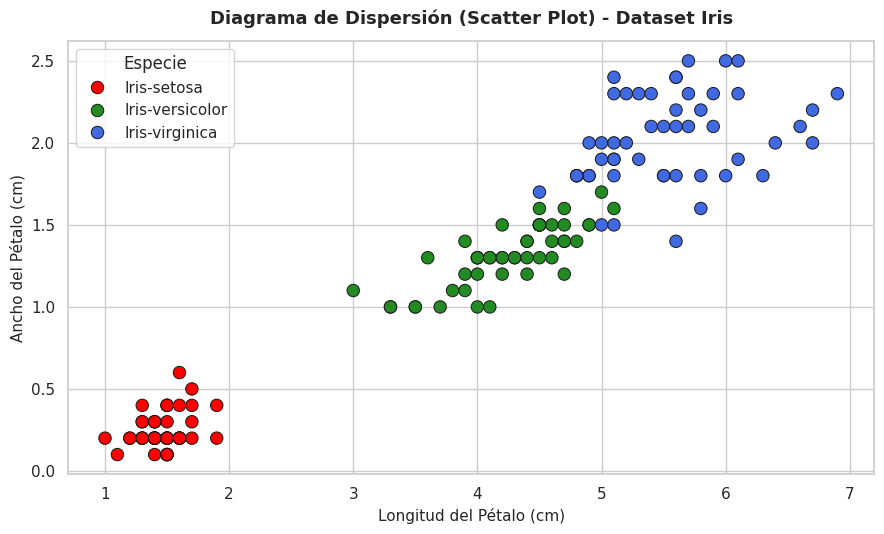

In [2]:
# 1. Carga del dataset Iris desde URL pública
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.csv"
columnas = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
df = pd.read_csv(url, header=None, names=columnas)

# Visualizamos las primeras filas
print("Primeras 5 filas del dataset Iris:")
display(df.head())

# Separación de variables de entrada X y etiquetas Y
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
target = 'species'
X = df[features].values
Y = df[target].values

print(f"\nDimensiones de X: {X.shape}")
print(f"Clases únicas: {np.unique(Y)}")

# 2. Diagrama de Dispersión (Scatter Plot)
# Usamos Longitud del Pétalo vs Ancho del Pétalo por ser el par con mayor poder de separación
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=df,
    x='petal_length',
    y='petal_width',
    hue='species',
    palette={'Iris-setosa': 'red', 'Iris-versicolor': 'forestgreen', 'Iris-virginica': 'royalblue'},
    s=80,
    edgecolor='k'
)
plt.title('Diagrama de Dispersión (Scatter Plot) - Dataset Iris', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Longitud del Pétalo (cm)', fontsize=11)
plt.ylabel('Ancho del Pétalo (cm)', fontsize=11)
plt.legend(title='Especie', loc='upper left')
plt.tight_layout()
plt.show()

### 3.2 Preprocesamiento de Datos

> **¿Qué cambia aquí?**
> 1. **Codificación One-Hot:** Las 3 clases de texto se convierten a vectores numéricos (ej. `Setosa` $\rightarrow [1, 0, 0]$).
> 2. **Splitting propio:** Dividimos 80% entrenamiento y 20% prueba de forma estratificada para balancear las 3 especies.
> 3. **Scaling manual:** Estandarizamos ($z = \frac{x - \mu}{\sigma}$) calculando $\mu$ y $\sigma$ únicamente en el conjunto de entrenamiento para evitar fuga de información (*data leakage*).

In [3]:
# 1. Codificación a índices enteros y One-Hot Encoding
especies = np.unique(Y)
mapa_clases = {esp: i for i, esp in enumerate(especies)}
y_indices = np.array([mapa_clases[s] for s in Y])

y_onehot = np.zeros((len(y_indices), len(especies)))
y_onehot[np.arange(len(y_indices)), y_indices] = 1.0

# 2. Partición Estratificada (80% entrenamiento, 20% prueba)
train_idx, test_idx = [], []
for c in range(len(especies)):
    miembros = np.where(y_indices == c)[0]
    np.random.shuffle(miembros)
    corte = int(len(miembros) * 0.80)
    train_idx.extend(miembros[:corte])
    test_idx.extend(miembros[corte:])

X_train, X_test = X[train_idx], X[test_idx]
Y_train_oh, Y_test_oh = y_onehot[train_idx], y_onehot[test_idx]
y_train, y_test = y_indices[train_idx], y_indices[test_idx]

# 3. Escalado Estándar manual (StandardScaler con NumPy)
mu = np.mean(X_train, axis=0)
sigma = np.std(X_train, axis=0)
sigma[sigma == 0] = 1.0

X_train_scaled = (X_train - mu) / sigma
X_test_scaled = (X_test - mu) / sigma

print("Datos divididos y escalados correctamente:")
print(f"Muestras de entrenamiento: {X_train_scaled.shape[0]}")
print(f"Muestras de prueba: {X_test_scaled.shape[0]}")

Datos divididos y escalados correctamente:
Muestras de entrenamiento: 120
Muestras de prueba: 30


### 3.3 Selección y Entrenamiento del Clasificador MLP From Scratch

> **¿Qué cambia aquí?**
> Se sustituye `MLPClassifier` por la clase `MLPFromScratch`, donde se estructuran los pasos de una red neuronal clásica:
> * `__init__`: Inicialización He de pesos $W$ y sesgos $b$.
> * `forward`: Paso hacia adelante combinando `relu` (capa oculta) y `softmax` (capa de salida).
> * `backward`: Cálculo de gradientes analíticos por regla de la cadena y actualización por Descenso de Gradiente.

Iniciando entrenamiento del Perceptrón Multicapa (1000 épocas)...
Época    1/1000 - Loss: 0.9810
Época  200/1000 - Loss: 0.1323
Época  400/1000 - Loss: 0.0770
Época  600/1000 - Loss: 0.0599
Época  800/1000 - Loss: 0.0518
Época 1000/1000 - Loss: 0.0469
✅ Entrenamiento completado. Pérdida final: 0.0469


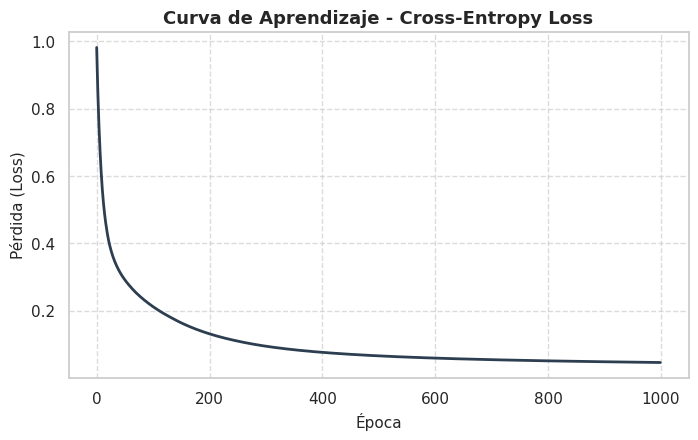

In [4]:
# Implementación de la clase Perceptrón Multicapa (MLP) From Scratch
class MLPFromScratch:
    def __init__(self, input_dim=4, hidden_dim=10, output_dim=3, learning_rate=0.08, epochs=1000):
        self.lr = learning_rate
        self.epochs = epochs
        self.loss_history = []

        # Inicialización de pesos y sesgos
        self.W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
        self.b2 = np.zeros((1, output_dim))

    def _relu(self, z):
        return np.maximum(0, z)

    def _softmax(self, z):
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def forward(self, X):
        self.Z1 = np.dot(X, self.W1) + self.b1
        self.A1 = self._relu(self.Z1)
        self.Z2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = self._softmax(self.Z2)
        return self.A2

    def backward(self, X, y_oh):
        m = X.shape[0]
        # Gradiente en la salida
        dZ2 = self.A2 - y_oh
        dW2 = (1.0 / m) * np.dot(self.A1.T, dZ2)
        db2 = (1.0 / m) * np.sum(dZ2, axis=0, keepdims=True)

        # Gradiente en la capa oculta
        dA1 = np.dot(dZ2, self.W2.T)
        dZ1 = dA1 * (self.Z1 > 0)
        dW1 = (1.0 / m) * np.dot(X.T, dZ1)
        db1 = (1.0 / m) * np.sum(dZ1, axis=0, keepdims=True)

        # Actualización de pesos con Descenso de Gradiente
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def fit(self, X, y_oh):
        print(f"Iniciando entrenamiento del Perceptrón Multicapa ({self.epochs} épocas)...")
        for epoch in range(1, self.epochs + 1):
            probs = self.forward(X)
            loss = - (1.0 / X.shape[0]) * np.sum(y_oh * np.log(np.clip(probs, 1e-15, 1.0)))
            self.loss_history.append(loss)
            self.backward(X, y_oh)

            if epoch % 200 == 0 or epoch == 1:
                print(f"Época {epoch:4d}/{self.epochs} - Loss: {loss:.4f}")
        print(f"✅ Entrenamiento completado. Pérdida final: {self.loss_history[-1]:.4f}")

    def predict(self, X):
        probs = self.forward(X)
        return np.argmax(probs, axis=1)

# Instanciamos y entrenamos la red neuronal con las 4 características
mlp = MLPFromScratch(input_dim=4, hidden_dim=10, output_dim=3, learning_rate=0.08, epochs=1000)
mlp.fit(X_train_scaled, Y_train_oh)

# Gráfica de la curva de aprendizaje
plt.figure(figsize=(8, 4.5))
plt.plot(mlp.loss_history, color='#2c3e50', lw=2)
plt.title('Curva de Aprendizaje - Cross-Entropy Loss', fontsize=13, fontweight='bold')
plt.xlabel('Época', fontsize=11)
plt.ylabel('Pérdida (Loss)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 3.4 Evaluación del Modelo

> **¿Qué cambia aquí?**
> Las métricas se calculan sin `sklearn.metrics`:
> * **Accuracy:** Implementada directamente con `np.mean(y_test == y_pred)`.
> * **Matriz de Confusión:** Tabla de doble entrada acumulada con un bucle de NumPy y graficada con `sns.heatmap`.
> * **Fronteras de Decisión en 2D:** Se entrena el mismo modelo en 2D (`petal_length` y `petal_width`) y se grafica la malla continua de decisión idéntica al Colab original.

 Exactitud (Accuracy) del Modelo: 100.00%

--- MATRIZ DE CONFUSIÓN ---
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


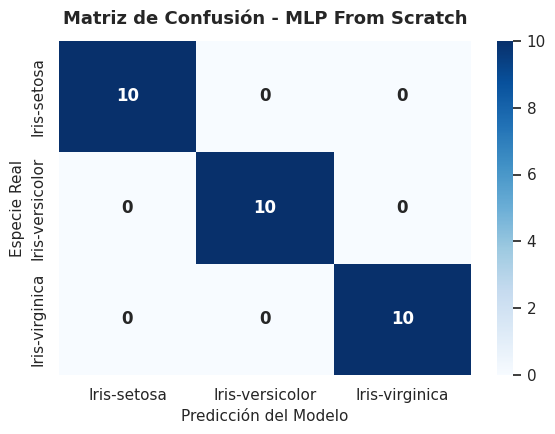

Iniciando entrenamiento del Perceptrón Multicapa (1200 épocas)...
Época    1/1200 - Loss: 1.7348
Época  200/1200 - Loss: 0.1215
Época  400/1200 - Loss: 0.0863
Época  600/1200 - Loss: 0.0765
Época  800/1200 - Loss: 0.0723
Época 1000/1200 - Loss: 0.0701
Época 1200/1200 - Loss: 0.0688
✅ Entrenamiento completado. Pérdida final: 0.0688


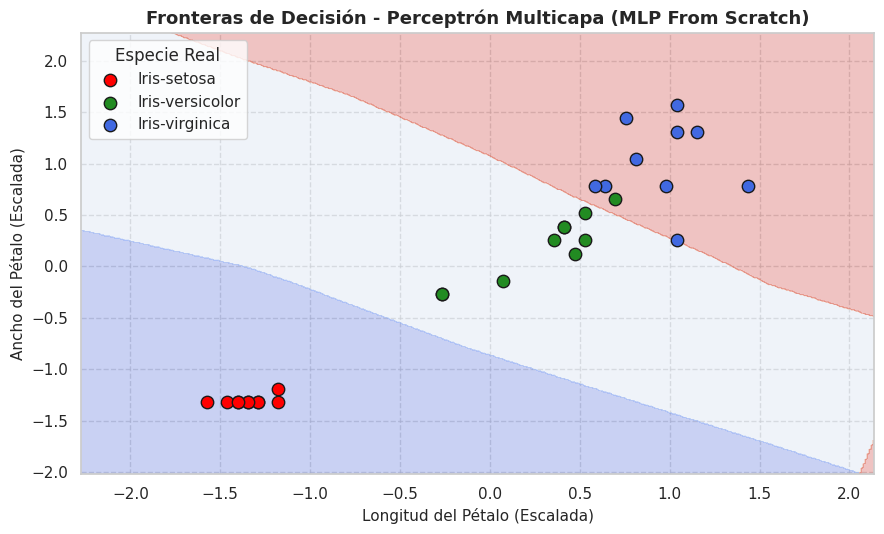

In [5]:
# 1. Predicciones en el conjunto de prueba
predictions = mlp.predict(X_test_scaled)

# 2. Cálculo de Accuracy From Scratch
accuracy = np.mean(y_test == predictions)
print(f" Exactitud (Accuracy) del Modelo: {accuracy * 100:.2f}%\n")

# 3. Matriz de Confusión From Scratch
conf_matrix = np.zeros((3, 3), dtype=int)
for real, pred in zip(y_test, predictions):
    conf_matrix[real, pred] += 1

print("--- MATRIZ DE CONFUSIÓN ---")
print(conf_matrix)

# Visualización de la Matriz de Confusión
plt.figure(figsize=(6, 4.5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=especies,
    yticklabels=especies,
    annot_kws={"size": 12, "weight": "bold"}
)
plt.title('Matriz de Confusión - MLP From Scratch', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicción del Modelo', fontsize=11)
plt.ylabel('Especie Real', fontsize=11)
plt.tight_layout()
plt.show()

# 4. Graficación de Fronteras de Decisión en 2D (Petal Length vs Petal Width)
# Seleccionamos las columnas 2 y 3
X_train_2d = X_train_scaled[:, 2:4]
X_test_2d = X_test_scaled[:, 2:4]

mlp_2d = MLPFromScratch(input_dim=2, hidden_dim=10, output_dim=3, learning_rate=0.08, epochs=1200)
mlp_2d.fit(X_train_2d, Y_train_oh)

# Generamos la malla cartesiana
x_min, x_max = X_test_2d[:, 0].min() - 0.7, X_test_2d[:, 0].max() + 0.7
y_min, y_max = X_test_2d[:, 1].min() - 0.7, X_test_2d[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid_points = np.c_[xx.ravel(), yy.ravel()]

Z = mlp_2d.predict(grid_points).reshape(xx.shape)

# Graficamos las regiones de decisión aprendidas
plt.figure(figsize=(9, 5.5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)

colores = {0: 'red', 1: 'forestgreen', 2: 'royalblue'}
for i, nombre in enumerate(especies):
    filtro = (y_test == i)
    plt.scatter(
        X_test_2d[filtro, 0],
        X_test_2d[filtro, 1],
        color=colores[i],
        label=nombre,
        edgecolor='k',
        s=80
    )

plt.title('Fronteras de Decisión - Perceptrón Multicapa (MLP From Scratch)', fontsize=13, fontweight='bold')
plt.xlabel('Longitud del Pétalo (Escalada)', fontsize=11)
plt.ylabel('Ancho del Pétalo (Escalada)', fontsize=11)
plt.legend(title='Especie Real', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()